<a href="https://colab.research.google.com/github/adrianfelsky/TrabalhosIA/blob/t2/Trabalho_Aprendizado_Bayesiano.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

## UFSC - Campus Blumenau
## Disciplina: CAC8002 - Inteligência Artificial

Aluno:

Adrian Gazzani Felsky dos Anjos (Equipe 3b)

# Carregar os datasets no Colab

In [ ]:
!git clone https://github.com/adrianfelsky/TrabalhosIA
!mv ./TrabalhosIA/ datasets

Cloning into 'TrabalhosIA'...
remote: Enumerating objects: 1290, done.
remote: Counting objects: 100% (66/66), done.
remote: Compressing objects: 100% (59/59), done.
remote: Total 1290 (delta 29), reused 20 (delta 6), pack-reused 1224 (from 2)
Receiving objects: 100% (1290/1290), 90.21 MiB | 42.30 MiB/s, done.
Resolving deltas: 100% (32/32), done.


# Exercício 1

In [ ]:
import pandas as pd
import numpy as np
from sklearn.model_selection import train_test_split

df = pd.read_csv('datasets/T2/chronic_kidney_disease/train/chronic_kidney_disease.csv', na_values=['?'])

# Filtrar os atributos para 3b (3, 4, 5, 20, 22, 24 e Classe 25)
# Convertendo para índice 0-based no Pandas: 2, 3, 4, 19, 21, 23, 24
indices_colunas = [2, 3, 4, 19, 21, 23, 24]
df_filtrado = df.iloc[:, indices_colunas].copy()

# Remover valores nulos para cálculo manual
df_filtrado.dropna(inplace=True)

# Separar Features (X) e Classe (y)
X = df_filtrado.iloc[:, :-1]
y = df_filtrado.iloc[:, -1]

# Separar 1/3 para teste
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.33, random_state=42)

# Implementação de Naive Bayes
def calcular_probabilidades_priori(y_train):
    classes = y_train.unique()
    priori = {}
    total = len(y_train)
    for c in classes:
        priori[c] = sum(y_train == c) / total
    return priori

def calcular_estatisticas(X_train, y_train):
    estatisticas = {}
    classes = y_train.unique()

    for c in classes:
        X_c = X_train[y_train == c]
        estatisticas[c] = {}
        for coluna in X_c.columns:
            if pd.api.types.is_numeric_dtype(X_c[coluna]):
                # Distribuição Gaussiana para numéricos
                estatisticas[c][coluna] = {
                    'media': X_c[coluna].mean(),
                    'desvio': X_c[coluna].std() + 1e-6
                }
            else:
                # Contagem de probabilidade para categóricos
                contagem = X_c[coluna].value_counts().to_dict()
                total_c = len(X_c)
                estatisticas[c][coluna] = {k: v / total_c for k, v in contagem.items()}
    return estatisticas

def calcular_probabilidade_condicional(x, stats_coluna):
    if 'media' in stats_coluna:
        media = stats_coluna['media']
        desvio = stats_coluna['desvio']
        exponente = np.exp(-((x - media) ** 2) / (2 * desvio ** 2))
        return (1 / (np.sqrt(2 * np.pi) * desvio)) * exponente
    else:
        return stats_coluna.get(x, 1e-6)

def prever_naive_bayes(X_test, priori, estatisticas):
    previsoes = []
    for _, linha in X_test.iterrows():
        probabilidades_posteriori = {}
        for c in priori:
            probabilidade = priori[c]
            for coluna in X_test.columns:
                valor = linha[coluna]
                prob_condicional = calcular_probabilidade_condicional(valor, estatisticas[c][coluna])
                probabilidade *= prob_condicional
            probabilidades_posteriori[c] = probabilidade
        classe_predita = max(probabilidades_posteriori, key=probabilidades_posteriori.get)
        previsoes.append(classe_predita)
    return previsoes

# Treinamento e Teste
prob_priori = calcular_probabilidades_priori(y_train)
estatisticas_treino = calcular_estatisticas(X_train, y_train)
previsoes = prever_naive_bayes(X_test, prob_priori, estatisticas_treino)

# Avaliação
acertos = sum(previsoes == y_test.values)
total_teste = len(y_test)
acuracia = acertos / total_teste

print("--- RESULTADO DO NAIVE BAYES ---")
print(f"Instâncias avaliadas: {total_teste}")
print(f"Taxa de acerto (Accuracy): {acuracia * 100:.2f}%")


--- RESULTADO DO NAIVE BAYES ---
Instâncias avaliadas: 99
Taxa de acerto (Accuracy): 82.83%


# Exercício 2

Configuração do weka:

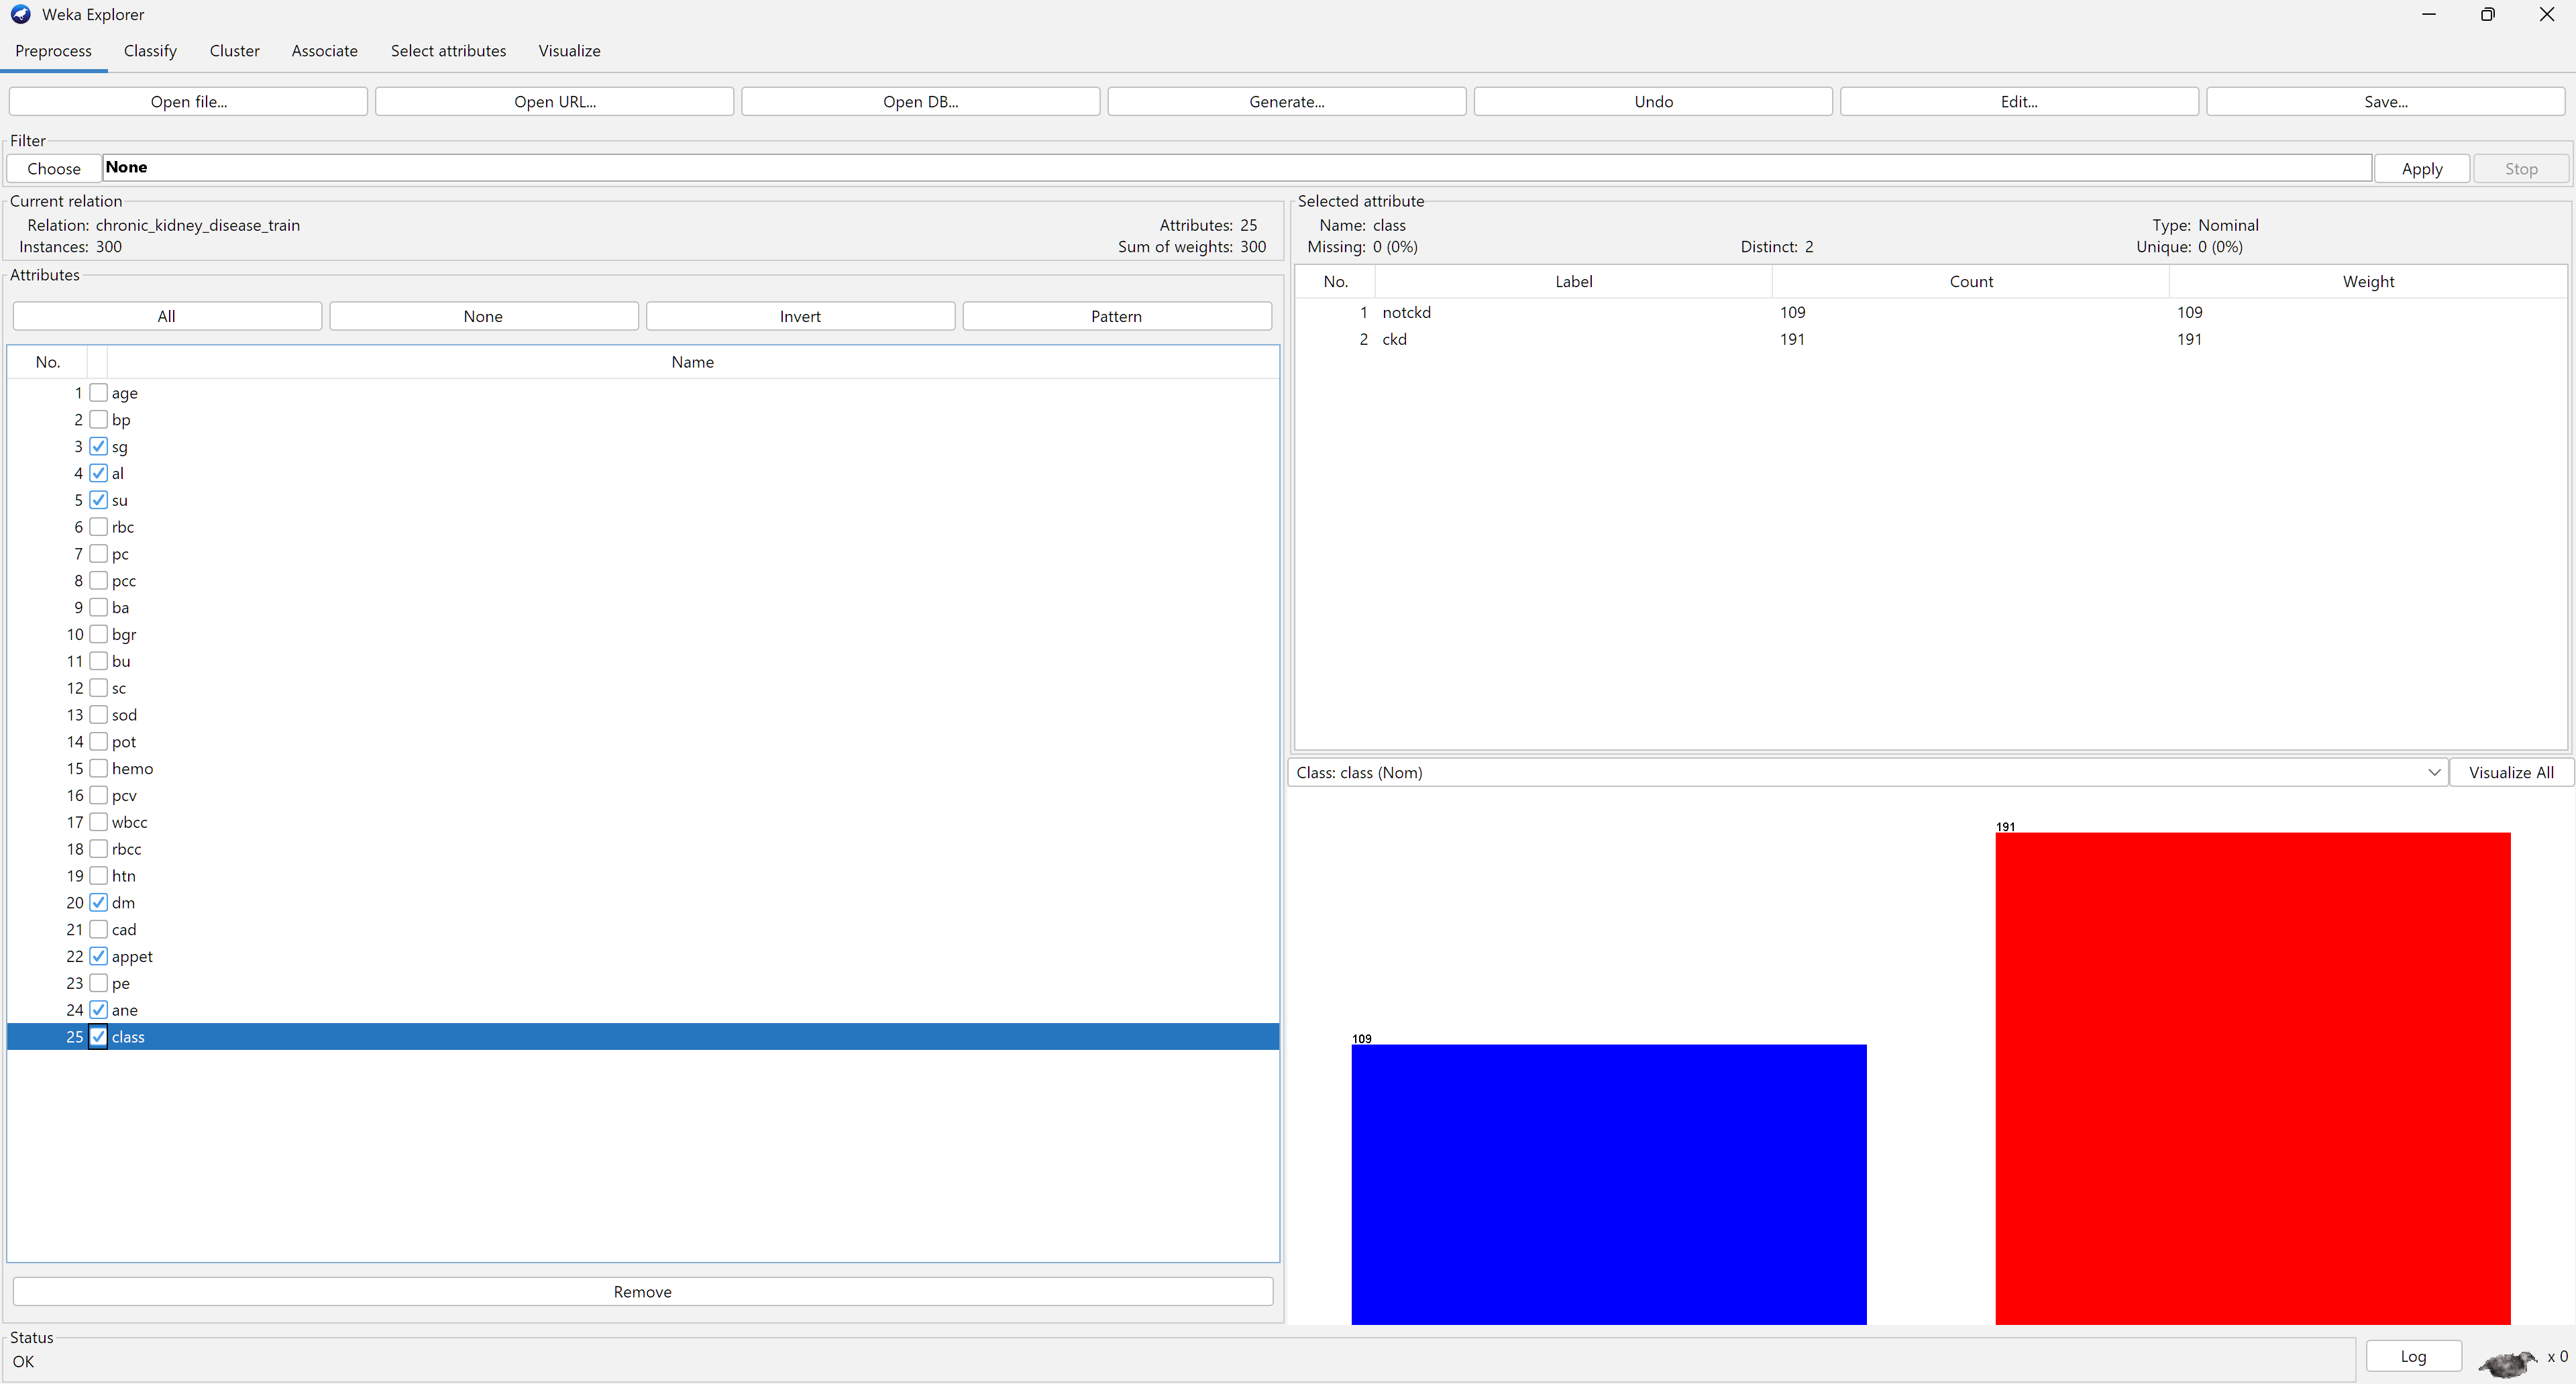

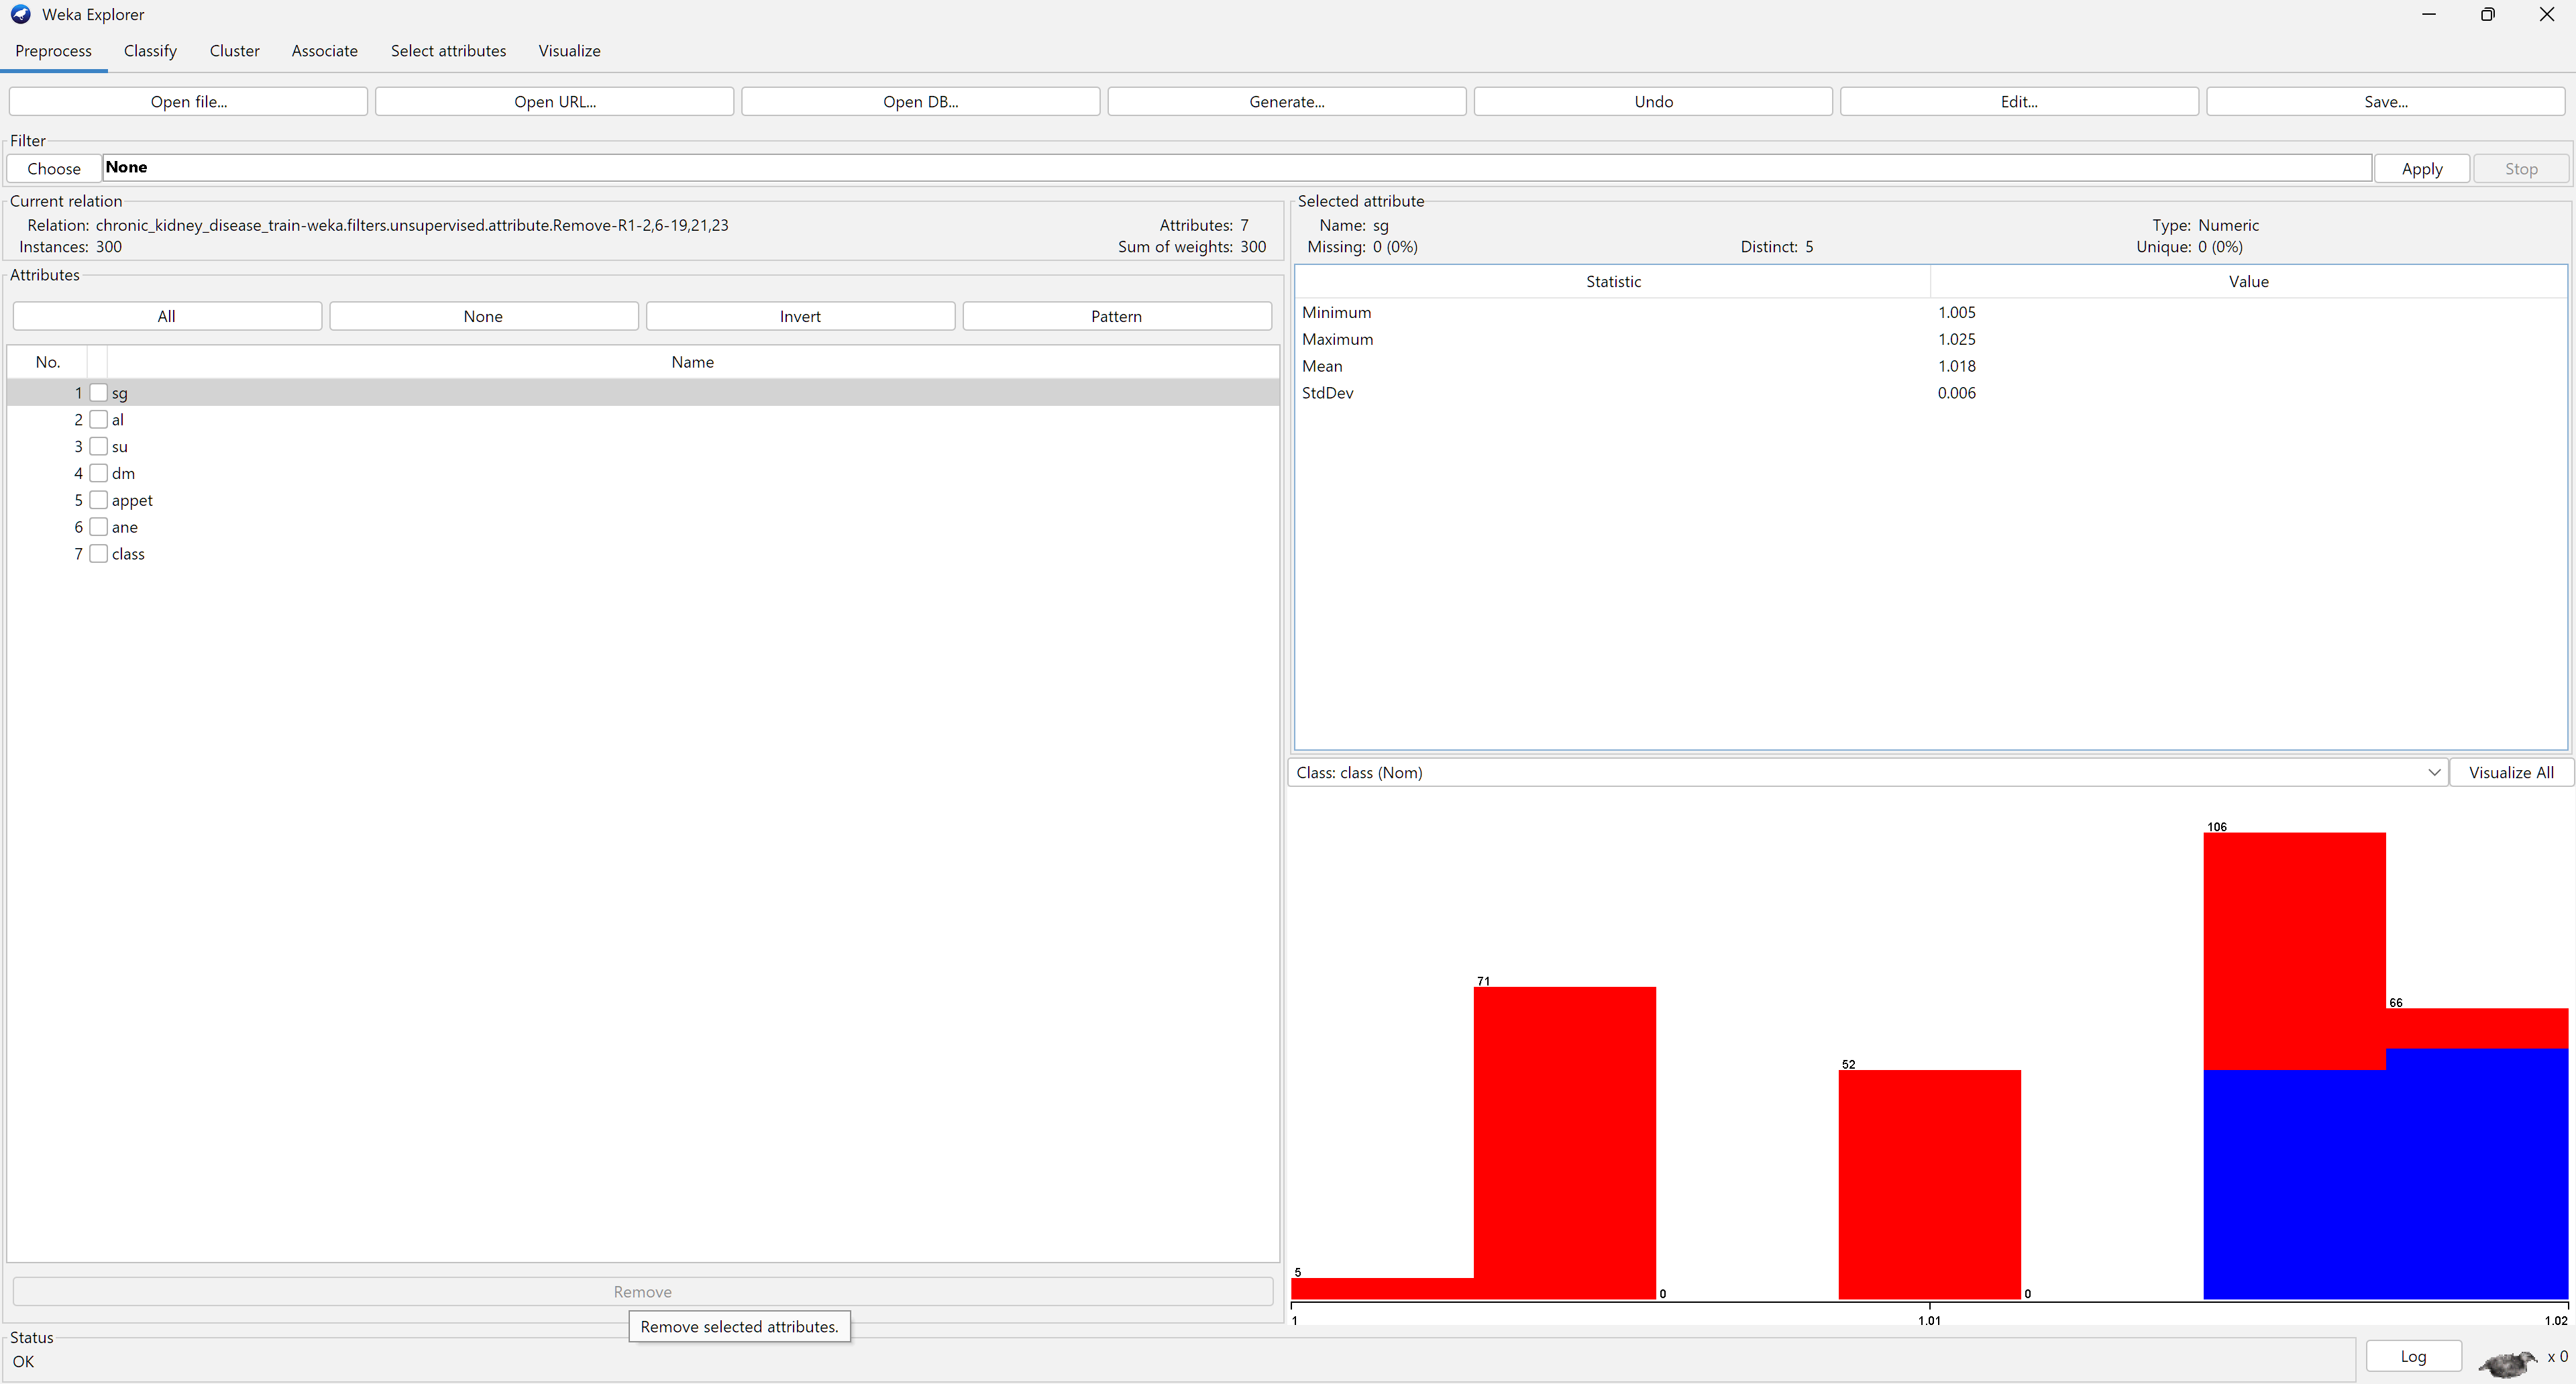

**Naive Bayes no WEKA:**

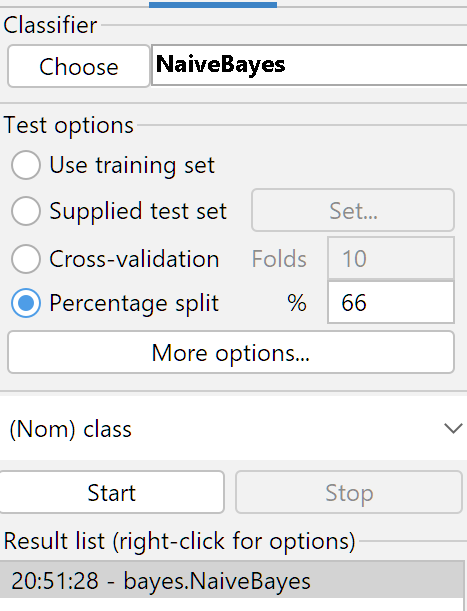

```

=== Run information ===

Scheme:       weka.classifiers.bayes.NaiveBayes
Relation:     chronic_kidney_disease_train-weka.filters.unsupervised.attribute.Remove-R1-2,6-19,21,23
Instances:    300
Attributes:   7
              sg
              al
              su
              dm
              appet
              ane
              class
Test mode:    split 66.0% train, remainder test

=== Classifier model (full training set) ===

Naive Bayes Classifier

                Class
Attribute      notckd    ckd
               (0.36) (0.64)
=============================
sg
  mean          1.0226 1.0148
  std. dev.     0.0025 0.0049
  weight sum       109    191
  precision      0.005  0.005

al
  mean               0 1.5183
  std. dev.     0.1667  1.421
  weight sum       109    191
  precision          1      1

su
  mean               0 0.5969
  std. dev.     0.1667 1.1933
  weight sum       109    191
  precision          1      1

dm
  no             110.0   93.0
  yes              1.0  100.0
  [total]        111.0  193.0

appet
  good           110.0  128.0
  poor             1.0   65.0
  [total]        111.0  193.0

ane
  no             110.0  146.0
  yes              1.0   47.0
  [total]        111.0  193.0



Time taken to build model: 0 seconds

=== Evaluation on test split ===

Time taken to test model on test split: 0 seconds

=== Summary ===

Correctly Classified Instances          90               88.2353 %
Incorrectly Classified Instances        12               11.7647 %
Kappa statistic                          0.7606
Mean absolute error                      0.0915
Root mean squared error                  0.266
Relative absolute error                 19.8115 %
Root relative squared error             55.6206 %
Total Number of Instances              102     

=== Detailed Accuracy By Class ===

                 TP Rate  FP Rate  Precision  Recall   F-Measure  MCC      ROC Area  PRC Area  Class
                 1,000    0,182    0,750      1,000    0,857      0,783    0,983     0,944     notckd
                 0,818    0,000    1,000      0,818    0,900      0,783    0,983     0,986     ckd
Weighted Avg.    0,882    0,064    0,912      0,882    0,885      0,783    0,983     0,971     

=== Confusion Matrix ===

  a  b   <-- classified as
 36  0 |  a = notckd
 12 54 |  b = ckd

```

**RESUMO**


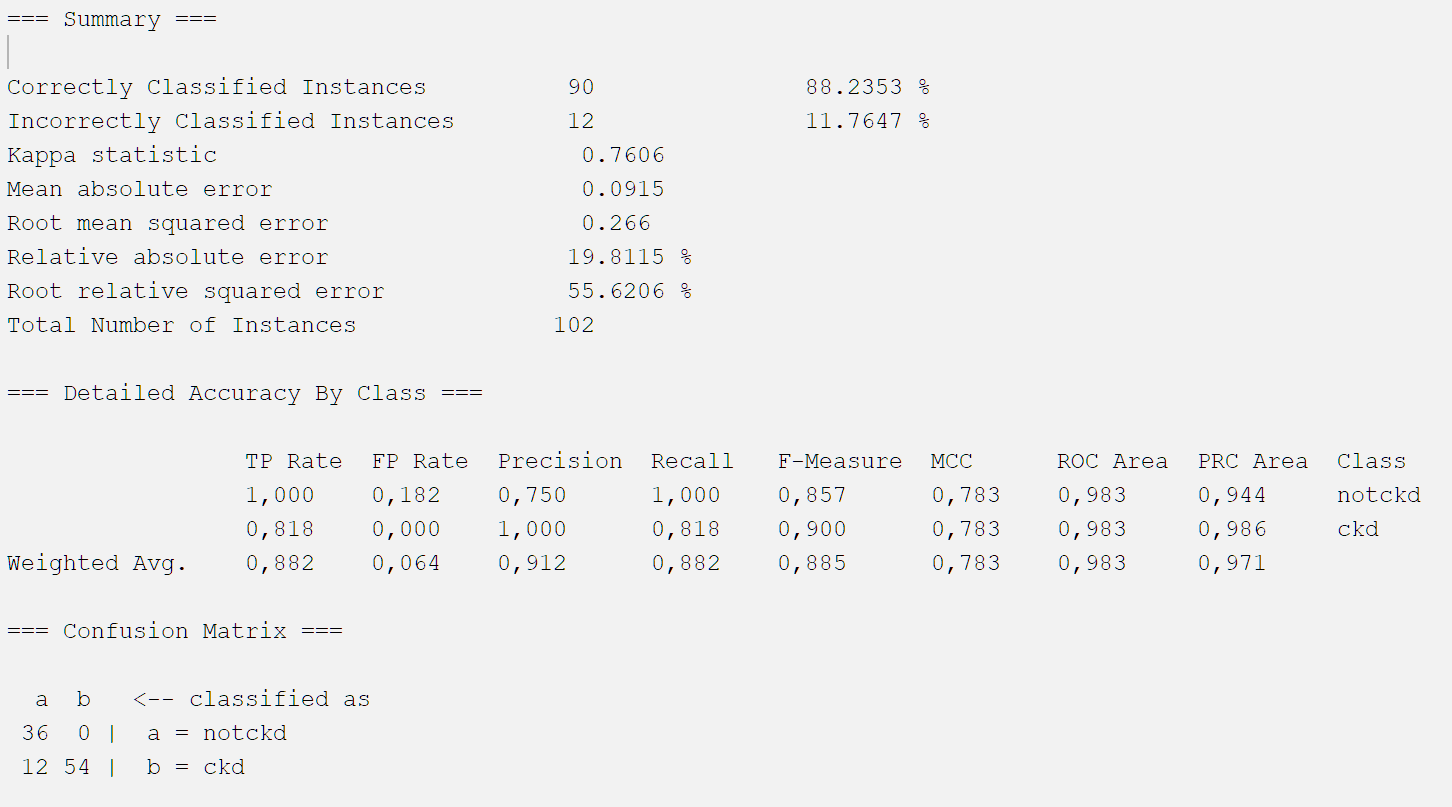

---
**Árvore de Decisão J48 no WEKA:**

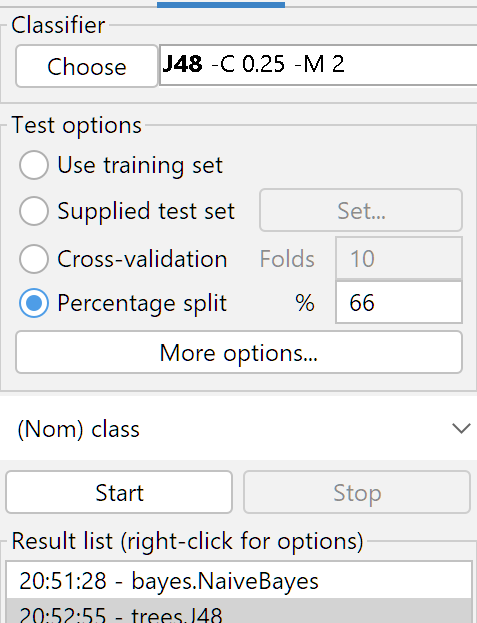


```

=== Run information ===

Scheme:       weka.classifiers.trees.J48 -C 0.25 -M 2
Relation:     chronic_kidney_disease_train-weka.filters.unsupervised.attribute.Remove-R1-2,6-19,21,23
Instances:    300
Attributes:   7
              sg
              al
              su
              dm
              appet
              ane
              class
Test mode:    split 66.0% train, remainder test

=== Classifier model (full training set) ===

J48 pruned tree
------------------

sg <= 1.015: ckd (128.0)
sg > 1.015
|   dm = no
|   |   al <= 0
|   |   |   appet = good: notckd (117.0/8.0)
|   |   |   appet = poor: ckd (4.0)
|   |   al > 0: ckd (13.0)
|   dm = yes: ckd (38.0)

Number of Leaves  : 	5

Size of the tree : 	9


Time taken to build model: 0.01 seconds

=== Evaluation on test split ===

Time taken to test model on test split: 0 seconds

=== Summary ===

Correctly Classified Instances          98               96.0784 %
Incorrectly Classified Instances         4                3.9216 %
Kappa statistic                          0.9163
Mean absolute error                      0.0555
Root mean squared error                  0.1903
Relative absolute error                 12.0219 %
Root relative squared error             39.788  %
Total Number of Instances              102     

=== Detailed Accuracy By Class ===

                 TP Rate  FP Rate  Precision  Recall   F-Measure  MCC      ROC Area  PRC Area  Class
                 1,000    0,061    0,900      1,000    0,947      0,919    0,970     0,900     notckd
                 0,939    0,000    1,000      0,939    0,969      0,919    0,970     0,979     ckd
Weighted Avg.    0,961    0,021    0,965      0,961    0,961      0,919    0,970     0,951     

=== Confusion Matrix ===

  a  b   <-- classified as
 36  0 |  a = notckd
  4 62 |  b = ckd

```

**RESUMO**

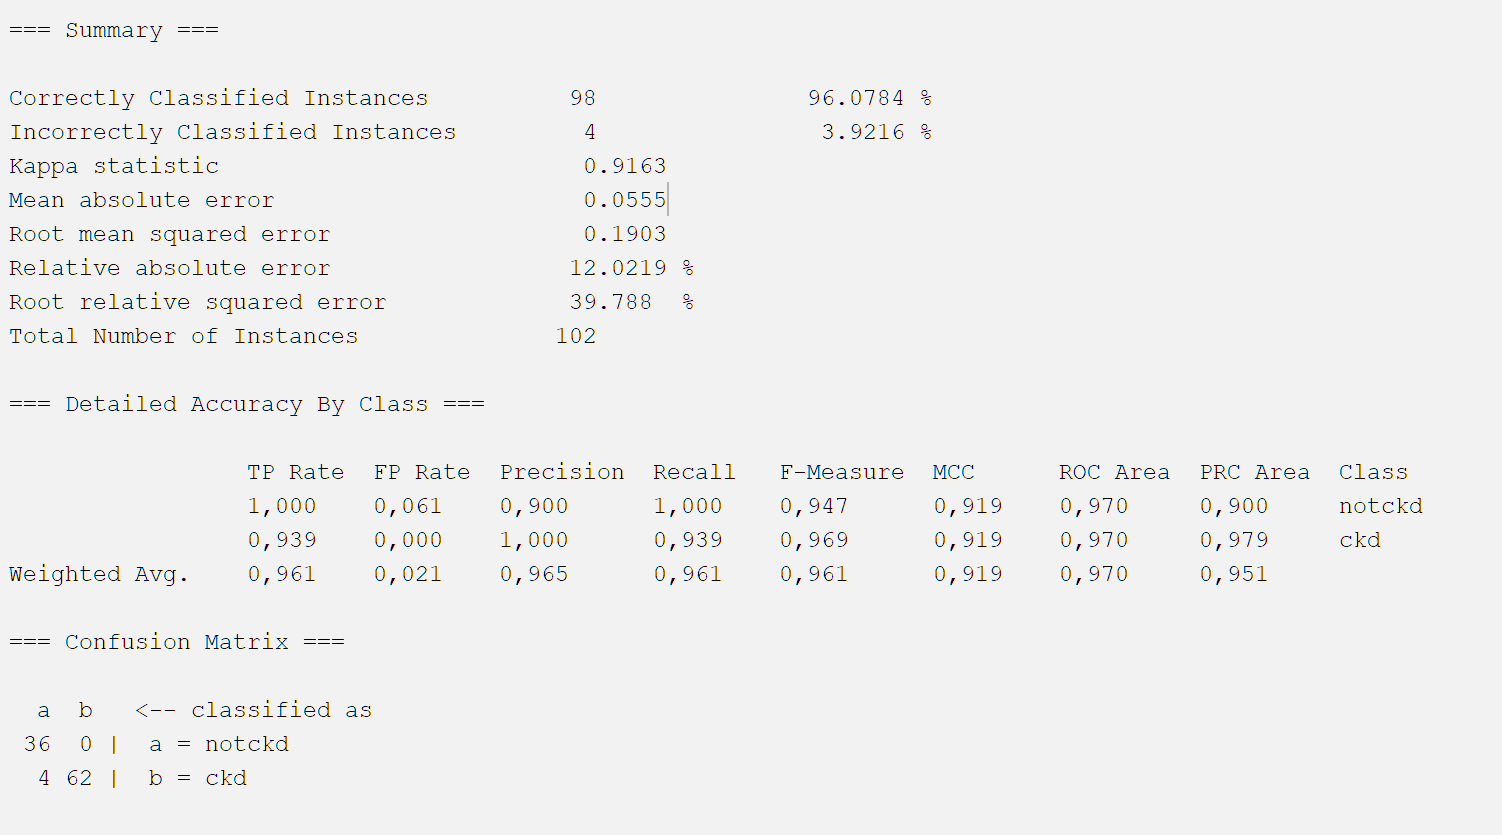

---
**Conclusão e Comparação:**

A implementação manual do Naive Bayes (Python) obteve uma acurácia de 82.83%, enquanto o classificador Naive Bayes no software Weka alcançou 88.24%. O algoritmo de Árvore de Decisão J48 obteve 96.08%.

Observa-se que o algoritmo de Árvore de Decisão J48 apresentou o melhor desempenho para esta configuração da base de dados Chronic Kidney Disease.

# Exercício 3

**Cenário Hipotético:**
Diagnóstico de falha operacional em um Torno CNC. A ocorrência de uma falha crítica na máquina e a consequente parada de produção dependem de dois fatores fundamentais: a estabilidade da rede elétrica da fábrica e a conformidade da rotina de manutenção preventiva do equipamento.

**Variáveis (Nós da Rede):**
1. Energia_Estavel (A rede elétrica está estável?) - *Nó Pai 1*
2. Manutencao_Dia (A manutenção preventiva do torno CNC está em dia?) - *Nó Pai 2*
3. Falha_Torno_CNC (O torno CNC apresentou falha?) - *Depende de 1 e 2*
4. Parada_Producao (Houve interrupção total na linha de produção?) - *Depende de 3*

---
### Rede Bayesiana Modelada (BayesEditor)

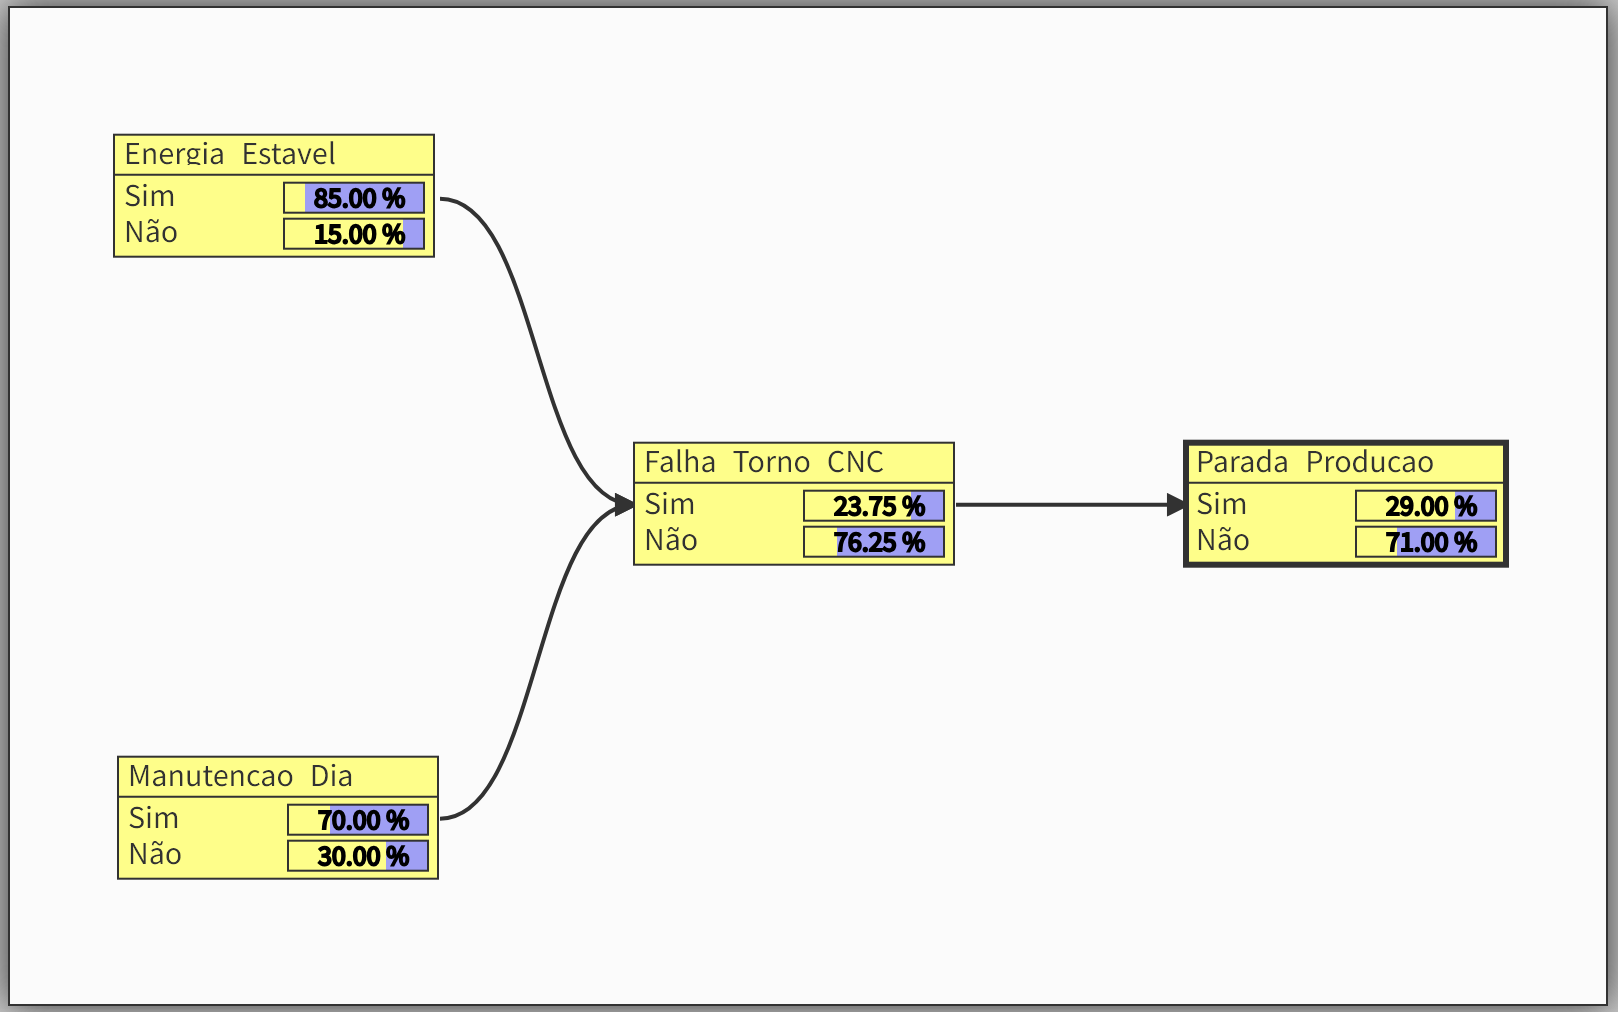

---
### Simulações de Cenários a 100%

**Cenário Simulado 1 (Evidência: Manutenção Preventiva 100% OK):**

Fixando-se o nó de `Manutenção em Dia` como 100% verdadeiro, as probabilidades de falha na máquina e parada da linha de produção caem consideravelmente.

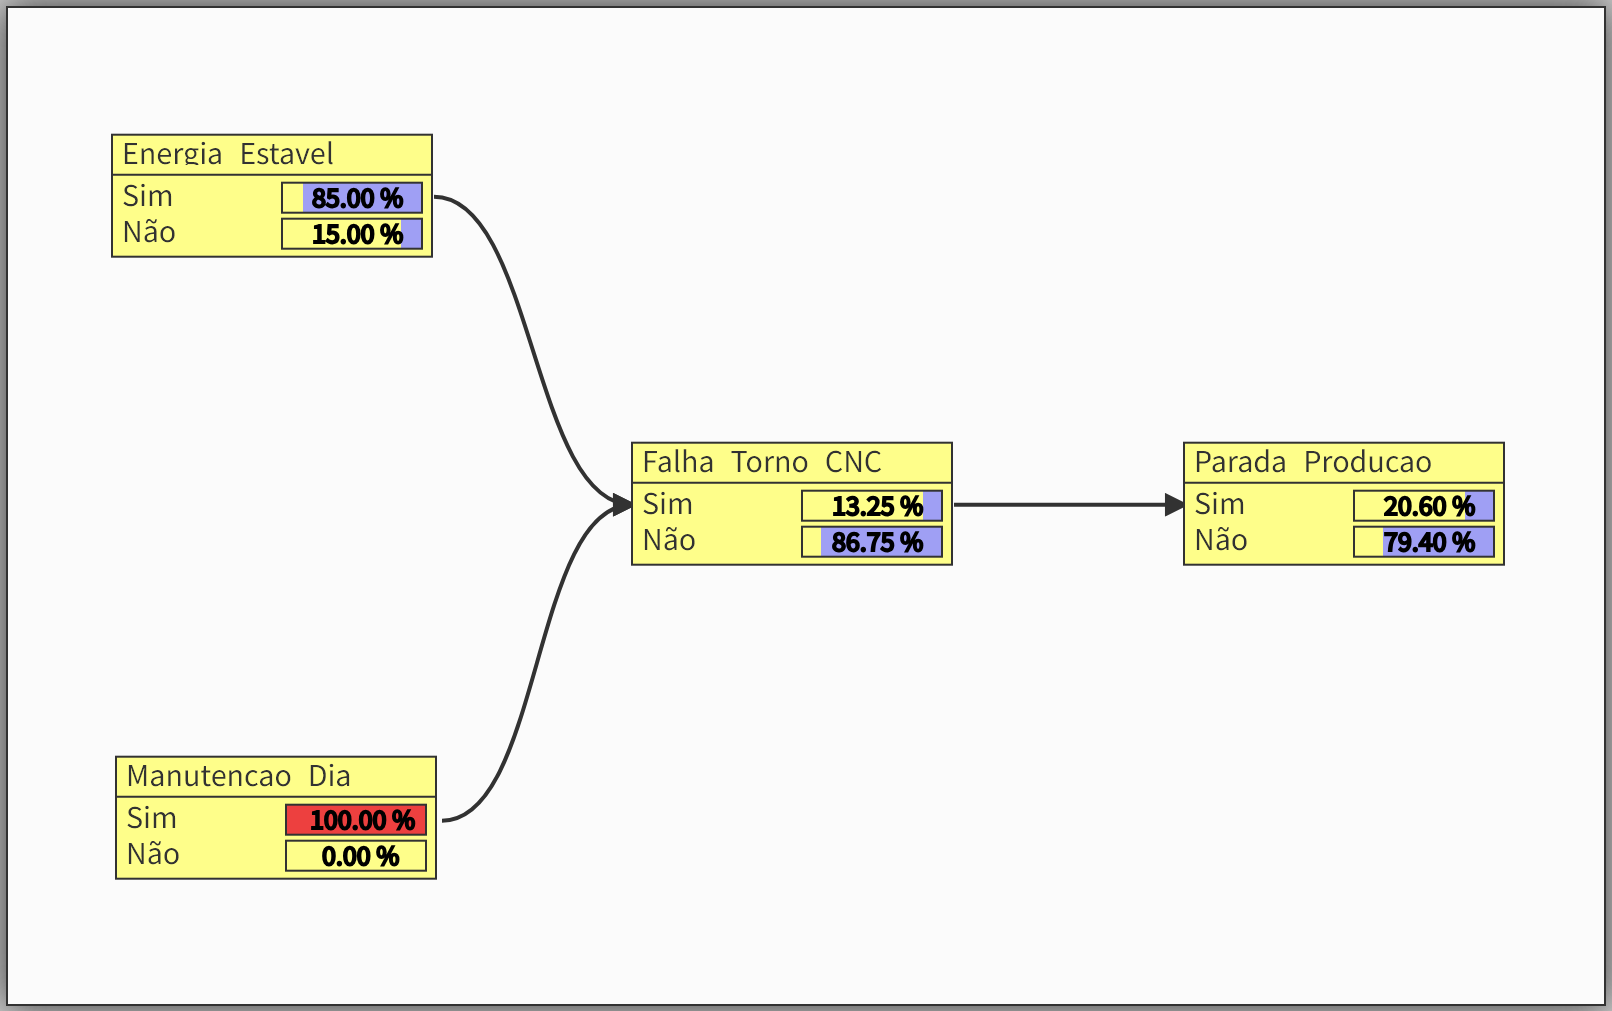

**Cenário Simulado 2 (Evidência: Energia Elétrica 100% Instável):**

Fixando-se o nó de `Energia Estável` como 100% falso, a probabilidade de apresentar falha no torno dispara para níveis de alto risco, refletindo diretamente na probabilidade de parada total da produção.

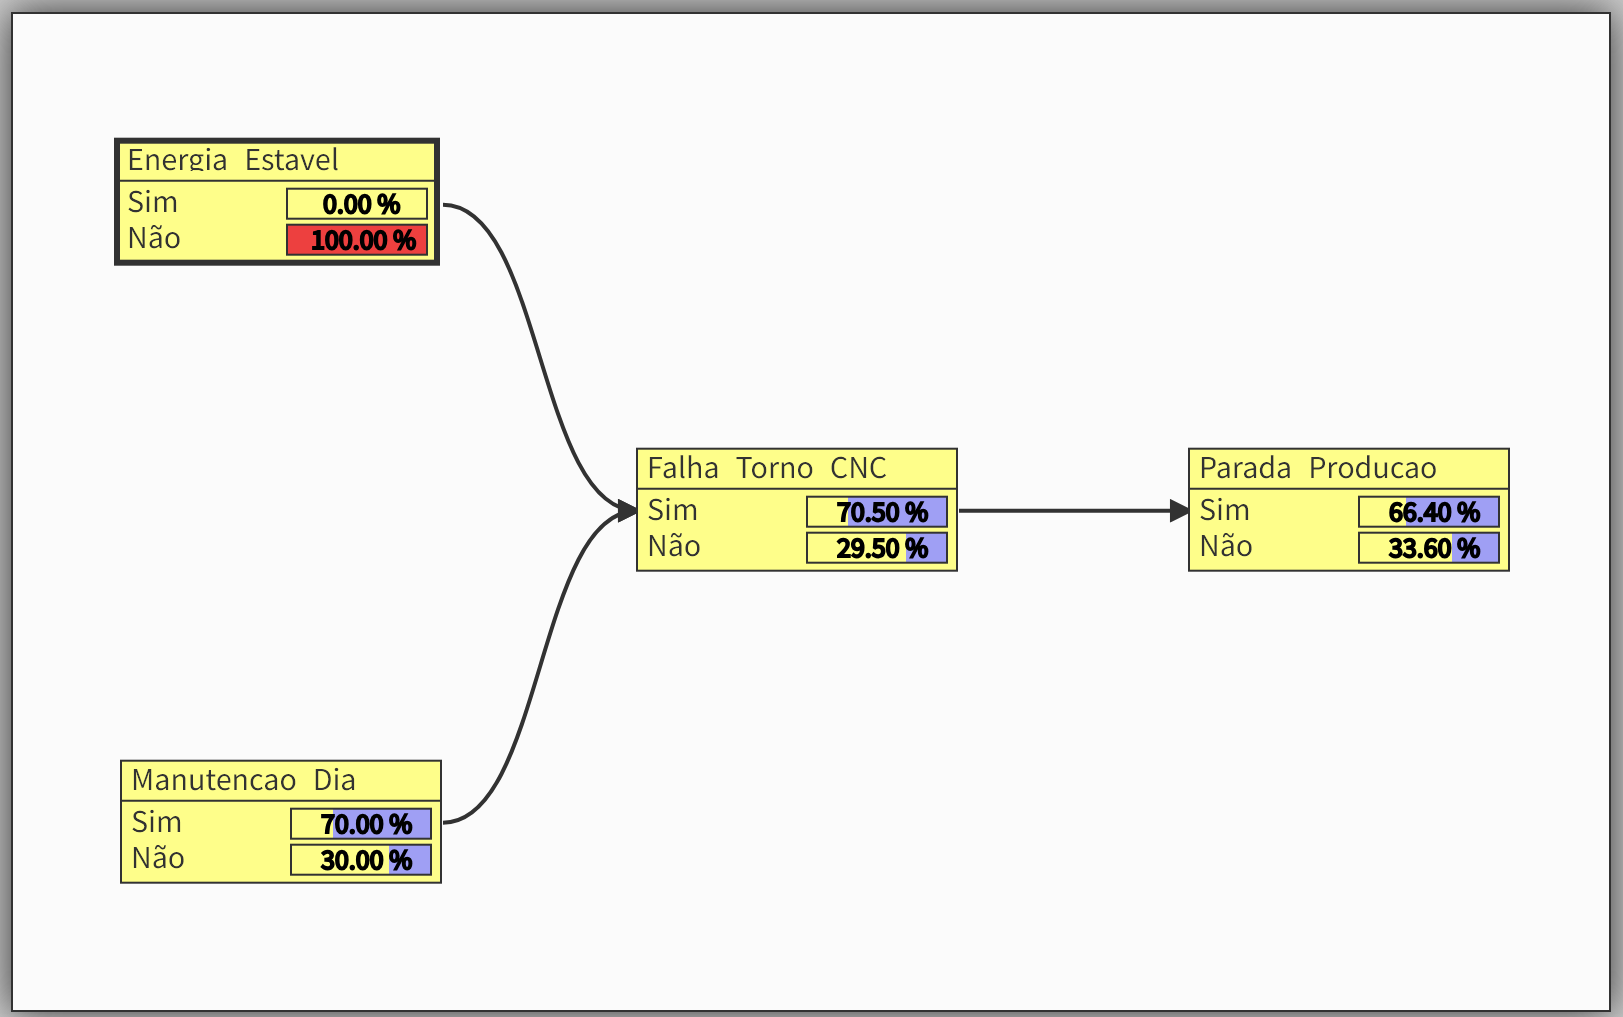